In [5]:
#sample business dataset

import pandas as pd

df = pd.DataFrame({
    "Student": ["Asha", "Rahul", "Sara", "Ali", "John", "Maya"],
    
    "Course": ["Python", "SQL", "Python", "Power BI", "SQL", "Python"],
    "Marks": [85, 70, 90, 60, 75, None],
    "Attendance": [90, 75, 95, 60, 80, 85],
    "Fee": [9000, 5000, 9000, 10000, 5000, 9000]
})

print(df)

  Student    Course  Marks  Attendance    Fee
0    Asha    Python   85.0          90   9000
1   Rahul       SQL   70.0          75   5000
2    Sara    Python   90.0          95   9000
3     Ali  Power BI   60.0          60  10000
4    John       SQL   75.0          80   5000
5    Maya    Python    NaN          85   9000


In [6]:
#data profiling

#checking the structure, quality and basic characteristics of the dataset before drawing conclusions.

print(df.head())          # First five rows
print(df.shape)           # Number of rows and columns
print(df.info())          # Data types and non-null counts
print(df.isnull().sum())  # Missing values per column
print(df.duplicated().sum())  # Duplicate rows

  Student    Course  Marks  Attendance    Fee
0    Asha    Python   85.0          90   9000
1   Rahul       SQL   70.0          75   5000
2    Sara    Python   90.0          95   9000
3     Ali  Power BI   60.0          60  10000
4    John       SQL   75.0          80   5000
(6, 5)
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Student     6 non-null      str    
 1   Course      6 non-null      str    
 2   Marks       5 non-null      float64
 3   Attendance  6 non-null      int64  
 4   Fee         6 non-null      int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 428.0 bytes
None
Student       0
Course        0
Marks         1
Attendance    0
Fee           0
dtype: int64
0


In [7]:
#Numerical Data
#describe() provides the count, mean, standard deviation, minimum, quartiles and maximum for numerical columns.
print(df[["Marks", "Attendance", "Fee"]].describe())


           Marks  Attendance           Fee
count   5.000000    6.000000      6.000000
mean   76.000000   80.833333   7833.333333
std    11.937336   12.416387   2228.601953
min    60.000000   60.000000   5000.000000
25%    70.000000   76.250000   6000.000000
50%    75.000000   82.500000   9000.000000
75%    85.000000   88.750000   9000.000000
max    90.000000   95.000000  10000.000000


In [8]:
#Categorical Data
#value_counts() counts the frequency of each unique value in a column.
#value_counts() returns counts. With normalize=True, it returns proportions instead.
print(df["Course"].value_counts())
print(df["Course"].value_counts(normalize=True) * 100)

Course
Python      3
SQL         2
Power BI    1
Name: count, dtype: int64
Course
Python      50.000000
SQL         33.333333
Power BI    16.666667
Name: proportion, dtype: float64


In [ ]:
#Univariate Analysis
#Univariate analysis means examining one variable at a time.

#- Distribution of marks.
#- Number of students in each course.
#- Distribution of attendance percentages.
#- Distribution of course fees.

count     5.000000
mean     76.000000
std      11.937336
min      60.000000
25%      70.000000
50%      75.000000
75%      85.000000
max      90.000000
Name: Marks, dtype: float64
Course
Python      3
SQL         2
Power BI    1
Name: count, dtype: int64


<Axes: title={'center': 'Distribution of Student Marks'}, ylabel='Frequency'>

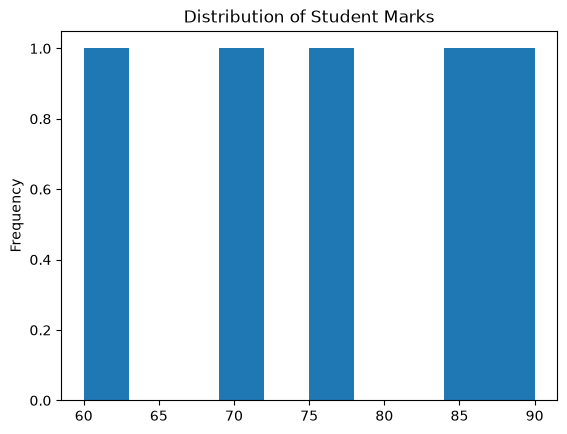

In [9]:
# One numerical variable
print(df["Marks"].describe())

# One categorical variable
print(df["Course"].value_counts())

# One variable's distribution in a chart
df["Marks"].dropna().plot(
    kind="hist",
    title="Distribution of Student Marks"
)

In [ ]:
#If we examine only the Marks column, are we studying the relationship between marks and attendance?"

            Attendance     Marks
Attendance    1.000000  0.994135
Marks         0.994135  1.000000
Course
Power BI    60.0
Python      87.5
SQL         72.5
Name: Marks, dtype: float64


<Axes: title={'center': 'Attendance vs Marks'}, xlabel='Attendance', ylabel='Marks'>

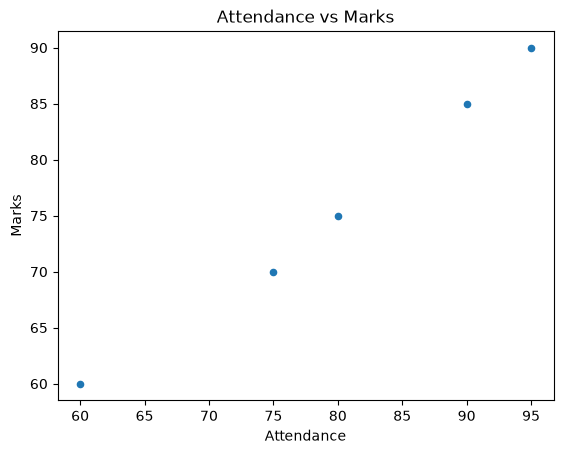

In [10]:
#bivariate analysis
#Bi = two. Bivariate analysis examines two variables together to understand whether they are related.

# Examine two numerical variables
print(df[["Attendance", "Marks"]].corr())

# Compare average marks across courses
print(df.groupby("Course")["Marks"].mean())

# Compare two numerical variables visually
df.plot(
    kind="scatter",
    x="Attendance",
    y="Marks",
    title="Attendance vs Marks"
)

#corr() measures the strength and direction of a linear relationship between numerical variables.

#groupby() lets us compare a numerical measure across categories.

#A scatter plot helps us visually inspect the relationship between two numerical variables.

In [11]:
#1. Data cleaning in EDA

import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Student": ["Asha", "Rahul", "Sara", "Ali", "John", "Maya", "Asha"],
    "Course": ["Python", "SQL", "Python", "Power BI", "SQL", "Python", "Python"],
    "Marks": [85, 70, 90, 60, np.nan, 150, 85],
    "Attendance": [90, 75, 95, 60, 80, 85, 90],
    "Fee": [9000, 5000, 9000, 10000, 5000, 9000, 9000]
})

print(df)

#A missing mark (NaN).
#A mark of 150, which is invalid if marks are out of 100.
#A possible duplicate record for Asha.

  Student    Course  Marks  Attendance    Fee
0    Asha    Python   85.0          90   9000
1   Rahul       SQL   70.0          75   5000
2    Sara    Python   90.0          95   9000
3     Ali  Power BI   60.0          60  10000
4    John       SQL    NaN          80   5000
5    Maya    Python  150.0          85   9000
6    Asha    Python   85.0          90   9000


In [12]:
#A. Detect missing values
print(df.isnull().sum())

Student       0
Course        0
Marks         1
Attendance    0
Fee           0
dtype: int64


In [13]:
#How to handle missing values
# Option 1: Remove rows with missing values
df_removed = df.dropna()

# Option 2: Fill missing marks with the median
df_filled = df.copy()
df_filled["Marks"] = df_filled["Marks"].fillna(
    df_filled["Marks"].median()
)
print(df_filled)
#dropna() removes records containing missing values, by default.
#fillna() replaces missing values with a chosen value.

  Student    Course  Marks  Attendance    Fee
0    Asha    Python   85.0          90   9000
1   Rahul       SQL   70.0          75   5000
2    Sara    Python   90.0          95   9000
3     Ali  Power BI   60.0          60  10000
4    John       SQL   85.0          80   5000
5    Maya    Python  150.0          85   9000
6    Asha    Python   85.0          90   9000


In [14]:
#B. Detect duplicate records
print(df.duplicated().sum())

print(df[df.duplicated()])

#Remove exact duplicate rows if they are genuine accidental duplicates:
df_clean = df.drop_duplicates()
print(df_clean)

1
  Student  Course  Marks  Attendance   Fee
6    Asha  Python   85.0          90  9000
  Student    Course  Marks  Attendance    Fee
0    Asha    Python   85.0          90   9000
1   Rahul       SQL   70.0          75   5000
2    Sara    Python   90.0          95   9000
3     Ali  Power BI   60.0          60  10000
4    John       SQL    NaN          80   5000
5    Maya    Python  150.0          85   9000


In [15]:
#C. Correct invalid values

df_valid = df[
    df["Marks"].between(0, 100) |
    df["Marks"].isna()
]

print(df_valid)

  Student    Course  Marks  Attendance    Fee
0    Asha    Python   85.0          90   9000
1   Rahul       SQL   70.0          75   5000
2    Sara    Python   90.0          95   9000
3     Ali  Power BI   60.0          60  10000
4    John       SQL    NaN          80   5000
6    Asha    Python   85.0          90   9000


In [ ]:
#2. Data visualization

#Visualization means representing data through charts so that patterns become easier to understand.

<Axes: title={'center': 'Distribution of Student Marks'}, ylabel='Frequency'>

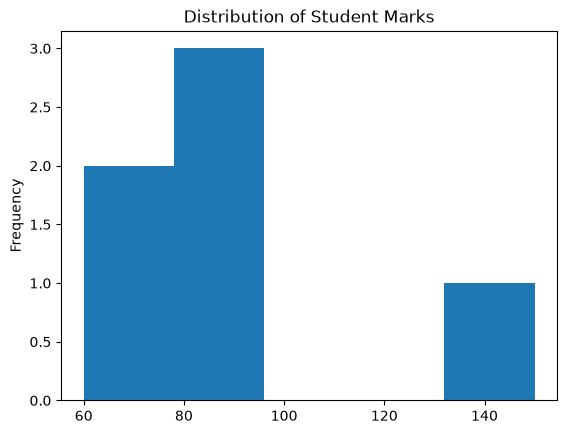

In [16]:
#A. Histogram — distribution of numerical data
df["Marks"].dropna().plot(
    kind="hist",
    bins=5,
    title="Distribution of Student Marks"
)

In [ ]:
#The x-axis shows mark ranges.
#The y-axis shows how many observations fall into each range.
#A histogram helps us see where values are concentrated and whether the distribution is skewed.

<Axes: title={'center': 'Box Plot of Student Marks'}>

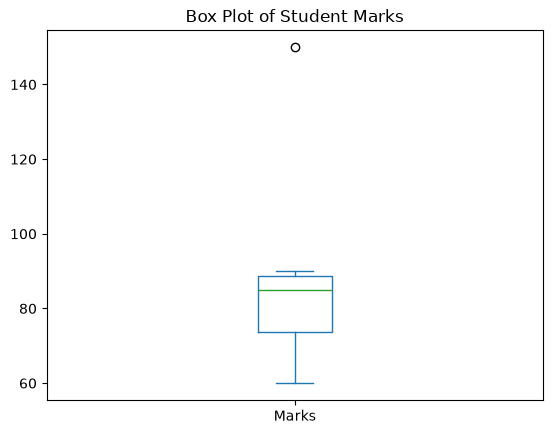

In [19]:
#B. Box plot 
#A Box Plot, also called a Box-and-Whisker Plot, is a graph used to understand the distribution of numerical data. It helps us identify:
#- The median (middle value)
#- The lower and upper quartiles
#- The spread of the data
#- Potential outliers
df["Marks"].dropna().plot(
    kind="box",
    title="Box Plot of Student Marks")

In [ ]:
#The line inside the box is the median.
#The box covers the 25th to 75th percentiles.
#The whiskers extend to values within the usual 1.5 × IQR rule.
#Points beyond the whiskers are potential outliers, not automatically errors.



#- Q1 = 13
#- Q3 = 25
#- IQR = 25 − 13 = 12
#Calculate the limits:

#Lower limit = 13-(1.5*12) =-5
#Upper limit}=25+(1.5*12) = 43

<Axes: title={'center': 'Students by Course'}, xlabel='Course'>

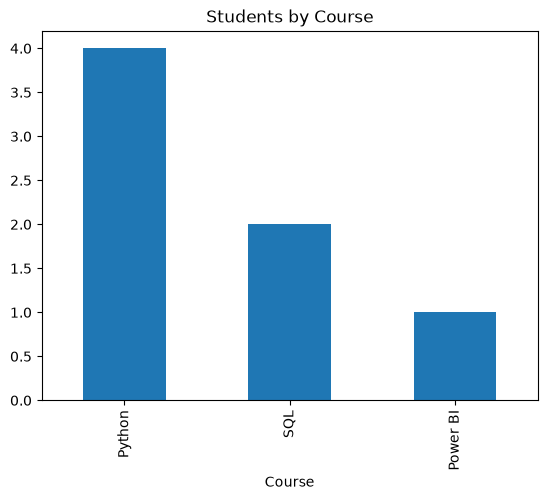

In [20]:
#C. Bar chart — compare categories

df["Course"].value_counts().plot(
    kind="bar",
    title="Students by Course"
)

#bar charts are suitable for categorical counts, whereas histograms are generally used for numerical distributions.

<Axes: title={'center': 'Attendance vs Marks'}, xlabel='Attendance', ylabel='Marks'>

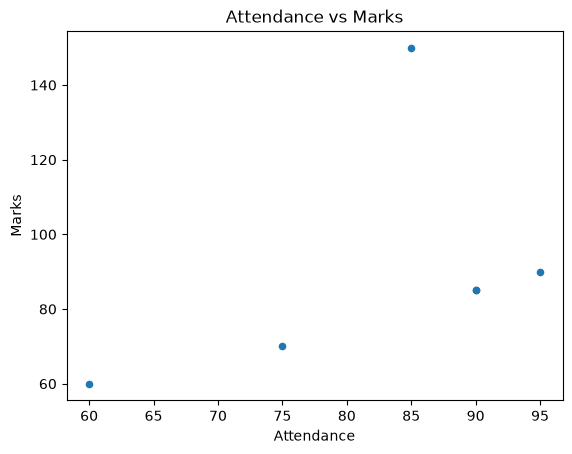

In [25]:
#D. Scatter plot — compare two numerical variables

df.plot(
    kind="scatter",
    x="Attendance",
    y="Marks",
    title="Attendance vs Marks"
)

#Each point represents one record. Students can inspect whether higher attendance tends to occur alongside higher marks, lower marks, or no clear pattern.

#A scatter plot can reveal a relationship, but it cannot establish that attendance causes higher marks.

In [ ]:
#Plot	              Data used	                         Main purpose
#Histogram	    One numerical variable	            Understand distribution
#Box plot	    One numerical variable	            Understand spread and potential outliers
#Bar plot	    Categories and their values/counts	Compare categories
#Scatter plot   Two numerical variables	            Explore relationships

In [ ]:
#3. Outlier detection using the IQR method

#An outlier is an observation that is unusually far from the rest of the data.

#IQR stands for Interquartile Range. It measures the spread of the middle 50% of the data.

#IQR=Q_3-Q_1
#Q_1: 25th percentile.
#Q_3: 75th percentile.

In [21]:
marks = pd.Series([45, 50, 55, 60, 65, 70, 98])

Q1 = marks.quantile(0.25)
Q3 = marks.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = marks[
    (marks < lower_bound) |
    (marks > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Potential outliers:", outliers.tolist())

Q1: 52.5
Q3: 67.5
IQR: 15.0
Potential outliers: [98]


In [ ]:
#4. Correlation analysis
#Correlation measures the direction and strength of a linear relationship between two numerical variables.

#Positive correlation: as one variable increases, the other tends to increase.
#Negative correlation: as one variable increases, the other tends to decrease.
#Little or no linear correlation: there is no clear linear relationship.

In [22]:
#The Pearson correlation coefficient ranges from \(-1\)
df[["Marks", "Attendance", "Fee"]].corr()
#Near +1: strong positive linear association.
#Near -1: strong negative linear association.
#Near 0: weak or no linear association.

,Marks,Attendance,Fee
Marks,1.000000,0.442026,0.180510
Attendance,0.442026,1.000000,0.101328
Fee,0.180510,0.101328,1.000000


In [23]:
#5. Categorical vs categorical analysis using cross-tabulation
#Suppose we want to know how many students from each city chose each course.
students = pd.DataFrame({
    "City": ["Hyderabad", "Chennai", "Hyderabad",
             "Mumbai", "Chennai", "Mumbai"],
    "Course": ["Python", "SQL", "SQL",
               "Python", "Python", "SQL"]
})

print(pd.crosstab(
    students["City"],
    students["Course"]
))

#pd.crosstab() creates a frequency table showing how two categorical variables occur together.

Course     Python  SQL
City                  
Chennai         1    1
Hyderabad       1    1
Mumbai          1    1


In [ ]:
#Business question: Do course preferences appear to differ by city?

In [24]:
#6. Grouped analysis using groupby() and agg()
#Suppose we want to compare courses using student count, average marks and average attendance.

summary = df.groupby("Course").agg(
    Student_Count=("Student", "count"),
    Average_Marks=("Marks", "mean"),
    Average_Attendance=("Attendance", "mean"),
    Highest_Marks=("Marks", "max")
)

print(summary.round(2))

#groupby("Course") divides the records by course.
#agg() calculates multiple summary measures for each group.
#round(2) displays numerical results to two decimal places.

          Student_Count  Average_Marks  Average_Attendance  Highest_Marks
Course                                                                   
Power BI              1           60.0                60.0           60.0
Python                4          102.5                90.0          150.0
SQL                   2           70.0                77.5           70.0


In [ ]:
#Univariate analysis: Study one variable, such as the distribution of marks.

#Bivariate analysis: Study two variables, such as attendance versus marks.

#Multivariate analysis: Study three or more variables together to understand a more complex picture.

In [ ]:
#A correlation heatmap is a colored table that helps us see the relationships between numerical variables.

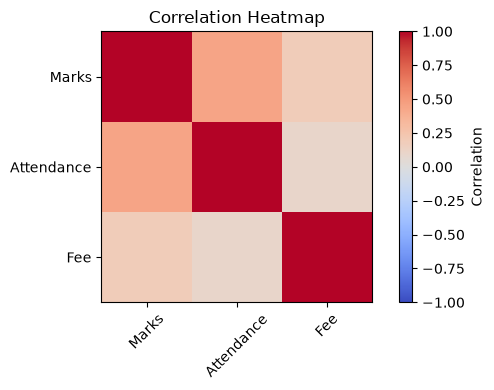

In [26]:
#7. Multivariate analysis
#Multivariate analysis examines three or more variables together.

import matplotlib.pyplot as plt

numeric_df = df[["Marks", "Attendance", "Fee"]]

correlation = numeric_df.corr()

plt.figure(figsize=(6, 4))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)),
           correlation.columns, rotation=45)
plt.yticks(range(len(correlation.columns)),
           correlation.columns)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

#numeric_df contains the three numerical columns.
#.corr() calculates the Pearson correlation between every pair of numerical columns.
#correlation stores the resulting table, called a correlation matrix.

In [ ]:
#Marks and Attendance = 0.90: strong positive linear relationship.
#Marks and Fee = 0.20: weak positive linear relationship.
#Attendance and Fee = 0.10: weak positive linear relationship.
#A variable correlated with itself has a value of 1.00.

In [ ]:
#Line 4: Set the figure size
#Line 5: Draw the heatmap
#correlation: the numerical table to display.
#cmap="coolwarm": uses a color gradient, generally blue for negative values and red for positive values, with lighter colors around zero.
#vmin=-1: sets the bottom of the color scale to −1.
#vmax=1: sets the top of the color scale to +1.
#Line 6: Display the color scale
#Line 7: Label the horizontal axis
#correlation.columns contains Marks, Attendance, and Fee.
#range(len(correlation.columns)) creates the positions for those labels.
#rotation=45 rotates the labels 45 degrees so they fit more neatly.
#Line 8: Label the vertical axis
#Line 10: Adjust spacing
#Line 11: Display the chart

In [ ]:
#8. Identifying business insights

#cleaned dataset shows:
#- Python has the highest number of enrolments.
#- One course has lower average attendance than the others.
#- Marks and attendance have a positive correlation.
#- Several fee records are missing.
    
#A good EDA report should distinguish between observation, interpretation and recommendation.
#Type	Example
#Observation	Course A has the lowest average attendance.
#Interpretation	Students in Course A may be attending less regularly.
#Recommendation	Investigate scheduling, trainer feedback and attendance patterns before deciding on an intervention.

#The observation comes from the data. 
#The interpretation is a possible explanation, not a proven cause. 
#The recommendation suggests what to investigate or do next.

In [ ]:
##Descriptive statistics

#Help us understand and summarize a dataset. Instead of looking at every value individually, 
#we use statistical measures to understand the data

import numpy as np
from statistics import multimode
marks = np.array([60, 70, 70, 80, 90])
print("Mean:", np.mean(marks))
print("Median:", np.median(marks))
print("Mode:", multimode(marks.tolist()))
print("Variance:", np.var(marks))
print("Standard deviation:", np.std(marks))
print("Range:", np.max(marks) - np.min(marks))
print("25th percentile:", np.percentile(marks, 25))
print("75th percentile:", np.percentile(marks, 75))

In [ ]:
#Mean	            Average marks
#Median	            Middle value after sorting
#Mode	            Most frequently occurring value
#Variance	        How spread out values are, measured in squared units
#Standard deviation	How far values typically spread around the mean
#Range	            Maximum minus minimum
#Percentile	        Position of a value within a dataset

In [ ]:
#Basic probability

#probability using a die.

#P(A)= Favourable outcomes / Total equally likely outcomes

#For a fair six-sided die:

#- Probability of getting 4 = 1/6
#- Probability of getting an even number = 3/6=0.5
#- Probability of getting a number greater than 4 = 2/6

#Rules

#- Probability ranges from 0 to 1.
#- Complement: P(not A) = 1-P(A)
#- For mutually exclusive events: P(A or B)= P(A) + P(B)
#- For independent events: P(A and B) = P(A) X P(B)

In [ ]:
#Normal, uniform and binomial distributions

#Normal distribution

#Data cluster around the average, forming a bell-shaped curve. 
# Example: approximately normally distributed measurement data.

#- loc = mean
#- scale = standard deviation

#Uniform distribution

#Values within a specified interval have equal probability density. 
# Example: generating random numbers between 0 and 1.

#- low = lower bound
#- high = upper bound


#Binomial distribution

#Counts the number of successes in a fixed number of independent trials, 
#each with the same success probability. 
#Example: number of heads in 10 coin tosses.

#- n = number of trials
#- p = probability of success

In [ ]:
import numpy as np

import matplotlib.pyplot as plt

np.random.seed(42)
normal = np.random.normal(loc=50, scale=10, size=1000)
uniform = np.random.uniform(low=0, high=100, size=1000)
binomial = np.random.binomial(n=10, p=0.5, size=1000)

plt.hist(normal, bins=20)
plt.title("Normal Distribution")
plt.show()

plt.hist(uniform, bins=20)
plt.title("Uniform Distribution")
plt.show()

plt.hist(binomial, bins=range(12), align="left")
plt.title("Binomial Distribution: Number of Successes")
plt.xticks(range(11))
plt.show()

In [ ]:
#Feature	 Normal	        Uniform	                    Binomial
#----------------------------------------------------------------------
#Shape	     Bell-shaped	Flat	                    Discrete bars
#Values	     Continuous	    Continuous or discrete	    Discrete counts
#Pattern	 Most values    near average	            Equal probability across possible values	Counts successes
#Example	 Exam marks	    Random number from 0–100	Heads in 5 tosses

In [ ]:
#Central Limit Theorem (CLT)

#When we repeatedly take sufficiently large random samples from a population and calculate the mean of each sample, 
#the distribution of those sample means becomes approximately normal (bell-shaped), under suitable conditions."

#Instead of calculating the average marks of all 1,000 students:
#1. Randomly select 30 students.
#2. Calculate their average marks.
#3. Select another 30 students.
#4. Calculate their average marks again.
#5. Repeat this process many times.


import numpy as np
import matplotlib.pyplot as plt

# Original population
population = np.random.exponential(
    scale=50,
    size=10000
)

sample_means = []

# Take 1000 samples
for i in range(1000):

    sample = np.random.choice(
        population,
        size=30
    )

    sample_means.append(np.mean(sample))

# Plot sample means
plt.hist(sample_means, bins=30)
plt.title("Central Limit Theorem")
plt.xlabel("Sample Means")
plt.ylabel("Frequency")
plt.show()


#population → Original data.
#np.random.choice() → Randomly selects 30 values.
#np.mean() → Calculates the average of those 30 values.
#sample_means → Stores the averages from all 1,000 samples.

In [ ]:
#1. Confidence Interval
#A confidence interval is a range of values that we use to estimate the actual average of a population based on a sample.
    
import numpy as np
from scipy import stats

#SciPy (Scientific Python)

marks = [65, 70, 75, 68, 72, 80, 69, 74, 71, 76]

mean = np.mean(marks)

confidence_interval = stats.t.interval(
    confidence=0.95,
    df=len(marks)-1,
    loc=mean,
    scale=stats.sem(marks)
)

print("Mean:", mean)
print("95% Confidence Interval:", confidence_interval)


#confidence=0.95 → 95% confidence level.
#df=n-1 → Degrees of freedom.
#loc=mean → Sample mean.
#stats.sem(marks) → Standard error of the mean.

In [ ]:
#Hypothesis Testing
#Hypothesis testing is a statistical method used to check whether a statement or assumption about data is true or false based on sample information.

#"The average marks of our students are 70."

#------------Null Hypothesis (H₀)--------------

#This is the original statement or assumption.

#-----------Alternative Hypothesis (H₁)---------

#This is the opposite or competing statement.


#What is p-value?
#A p-value tells us how unusual our sample results would be if the null hypothesis were true.


#p-value	Decision
#Less than 0.05	Reject Null Hypothesis
#Greater than or equal to 0.05	Fail to Reject Null Hypothesis


from scipy import stats

marks = [65, 70, 75, 68, 72, 80, 69, 74, 71, 76]

result = stats.ttest_1samp(
    marks,
    popmean=70
)

print("T-statistic:", result.statistic)
print("P-value:", result.pvalue)

if result.pvalue < 0.05:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")


#ttest_1samp() compares the sample mean with a given value.
#popmean=70 is the assumed population mean.
#result.pvalue gives the p-value.
#We use the p-value to make our decision.

In [ ]:
#. ---------t-test---------

#A t-test is a statistical test used to compare the average values of groups and determine whether their difference is statistically significant.
    
    
from scipy import stats

batch_A = [60, 65, 70, 68, 72]
batch_B = [80, 85, 75, 90, 85]

result = stats.ttest_ind(
    batch_A,
    batch_B,
    equal_var=False
)

print("T-statistic:", result.statistic)
print("P-value:", result.pvalue)

if result.pvalue < 0.05:
    print("Significant Difference")
else:
    print("No Significant Difference")


#batch_A → Marks of first batch.
#batch_B → Marks of second batch.
#ttest_ind() → Compares the means of two independent groups.
#equal_var=False → Uses Welch's t-test, which does not assume equal population variances.
#pvalue → Helps us make the statistical decision.

In [ ]:
#Topic	              What does it do?	    Example
#---------------------------------------------------------------------------
#Confidence Interval  Estimates a range	    Average marks may be between 64 and 76
#Hypothesis Testing	  Tests an assumption	Is the average marks really 70?
#t-test	              Compares averages	    Are Batch A and Batch B averages different?